In [82]:
import pandas as pd
import numpy as np
from numpy.polynomial import polynomial as P
import matplotlib.pyplot as plt

In [21]:
df = pd.read_csv("filtered_data_GIO.csv").drop(columns = 'Unnamed: 0')
df.columns.tolist()

['Well',
 'Time',
 'Temp',
 'OD',
 'Sample',
 'Replicate',
 'Group',
 'X',
 'X.1',
 'OD_corrected']

In [ ]:
df['Sample'].unique()


array(['V2_C25.1_P5', 'V2_P20.7_P5', 'MEDIA', 'V2_C20.4_P5',
       'V2_C25.4_P5', 'V2_C25.7_P5', 'V2_P20.3_P5', 'V2_P25.4_P5',
       'V2_C25.6_P5', 'V2_C20.5_P5', 'V2_C20.7_P5', 'V2_C20.1_P5',
       'V2_C20.2_P5', 'ANC', 'V2_C20.8_P5', 'V2_P20.1_P5', 'V2_C25.5_P5',
       'V2_C25.9_P5', 'V2_P25.2_P5', 'V2_P25.5_P5', 'V2_P25.3_P5',
       'V2_P25.1_P5', 'V2_P20.2_P5', 'V2_P20.4_P5', 'V2_P20.5_P5',
       'V2_P25.6_P5'], dtype=object)

In [185]:
slopesdf = pd.DataFrame(columns = ['Sample', 'Well', 'inflection_slope'])

for sample in df['Sample'].unique():
    df_sample = df[df['Sample'] == sample]
    myvar = df_sample['Well'].unique().tolist()
    
    for i in range(len(myvar)):
        my_df = df_sample[df_sample['Well'] == myvar[i]]

        p = P.Polynomial.fit(my_df['Time'], my_df['OD_corrected'], deg=3)
        p_der_2_coeff = P.polyder(p.convert().coef, m=2)
        p_der_1_coeff = P.polyder(p.convert().coef, m=1)
        p_der = P.Polynomial(p_der_1_coeff)
        critical_point = np.roots(np.flip(p_der_2_coeff))
        p_der_at_crit = p_der(critical_point)

        new_row = {'Sample': sample, 'Well': myvar[i], 'inflection_slope': p_der_at_crit}
        new_row = pd.DataFrame([new_row])
        slopesdf = pd.concat([slopesdf, new_row], ignore_index=True)

slopesdf

,Sample,Well,inflection_slope
0,V2_C25.1_P5,A1,[0.026121330259939415]
1,V2_C25.1_P5,B9,[0.02927432300295102]
2,V2_C25.1_P5,G10,[0.03773464766125433]
3,V2_P20.7_P5,A10,[0.023196910516993755]
4,V2_P20.7_P5,A7,[0.021745750027002898]
...,...,...,...
88,V2_P20.5_P5,F3,[0.025966452807577242]
89,V2_P20.5_P5,H6,[0.027913831161080517]
90,V2_P25.6_P5,F12,[0.021057995476682592]
91,V2_P25.6_P5,G6,[0.022869545275271373]


In [ ]:
#slopesdf.to_csv('sample_slopes.csv', index=False)


Coefficients for well A10:  [ 2.86281437e-02 -1.67704807e-02  3.18894662e-03 -8.48139800e-05]
critical points:  [12.53310135]
slope at crit:  [0.02319691]

Coefficients for well A7:  [ 2.88738609e-02 -1.47759639e-02  2.83793037e-03 -7.35074005e-05]
critical points:  [12.86913673]
slope at crit:  [0.02174575]

Coefficients for well C4:  [ 6.18926292e-03  4.71071769e-03  1.50087648e-03 -3.23082641e-05]
critical points:  [15.48495946]
slope at crit:  [0.02795173]



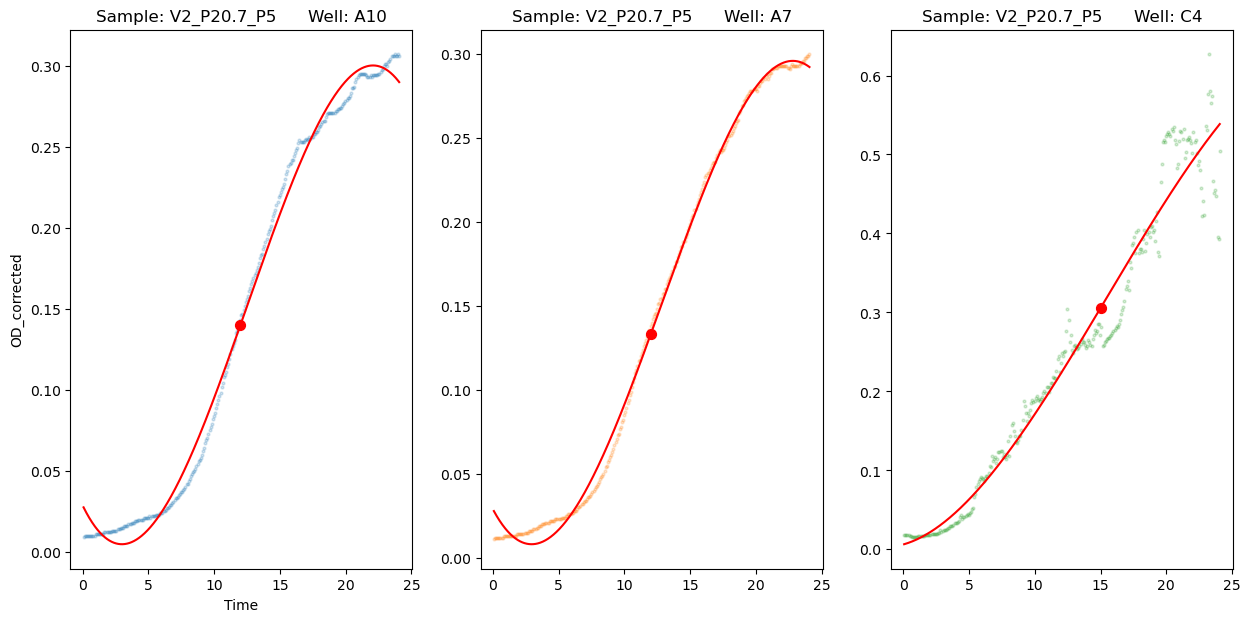

In [ ]:
#Choose the sample whose plots you want to view
sample = 'V2_P20.7_P5'


df_sample = df[df['Sample'] == sample]
myvar = df_sample['Well'].unique().tolist()
mycolors = ['C0','C1','C2']

plt.figure(figsize=(15,7))
for i in range(len(myvar)):
    plt.subplot(1,len(myvar),i+1)
    my_df = df_sample[df_sample['Well'] == myvar[i]]

    p = P.Polynomial.fit(my_df['Time'], my_df['OD_corrected'], deg=3)
    p_der_2_coeff = P.polyder(p.convert().coef, m=2)
    p_der_1_coeff = P.polyder(p.convert().coef, m=1)
    p_der = P.Polynomial(p_der_1_coeff)
    critical_point = np.roots(np.flip(p_der_2_coeff))
    p_der_at_crit = p_der(critical_point)

    print('Coefficients for well '+str(myvar[i])+': ', p.convert().coef)
    print('critical points: ', critical_point)
    print('slope at crit: ', p_der_at_crit)
    print( )

    x = np.linspace(my_df['Time'].min(), my_df['Time'].max(), 1000)[:, np.newaxis]
    y = p(x)

    plt.scatter(my_df['Time'], my_df['OD_corrected'], s = 4, c=mycolors[i], alpha = 0.2)
    plt.title('Sample: ' + sample + '      Well: ' + str(myvar[i]))
    if i == 0:
        plt.xlabel('Time')
        plt.ylabel('OD_corrected')

    plt.plot(x,y, c='red')
    for n in range(len(critical_point)):
        plt.scatter(int(critical_point[n]), p(int(critical_point[n])), s=50, c='red')   
    plt.xlim(my_df['Time'].min()-1, my_df['Time'].max()+1) 